# Análisis Enriquecido de Charts Musicales — 2026-W46


In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

from scipy.stats import gaussian_kde

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12
plt.rcParams["figure.dpi"] = 100

YT_RED = "#FF0000"
YT_RED_DARK = "#CC0000"
YT_BG = "#FFFFFF"
YT_SURFACE = "#F9F9F9"
YT_TEXT = "#0F0F0F"
YT_GRAY = "#606060"
YT_GRID = "#E5E5E5"


def format_number(x):
    if pd.isna(x):
        return "N/A"
    if x >= 1_000_000_000:
        return f"{x / 1_000_000_000:.1f}B"
    if x >= 1_000_000:
        return f"{x / 1_000_000:.1f}M"
    if x >= 1_000:
        return f"{x / 1_000:.1f}K"
    return f"{x:,.0f}"


# Metric functions: try to import from the package, fall back to inline.
try:
    from core.metrics import (
        collaborations,
        general_stats,
        genre_stats,
        top_countries,
        top_countries_by_likes,
        top_songs,
        top_songs_by_country,
        video_metrics,
    )
except ImportError:
    # Self-contained fallback so the notebook runs when moved or opened
    # outside the repository (e.g. Colab).
    def general_stats(df):
        return {
            "total_songs": int(len(df)),
            "unique_countries": int(df["artist_country"].nunique()),
            "unique_genres": int(df["macro_genre"].nunique()),
            "total_views": int(df["views"].sum()),
            "total_likes": int(df["likes"].sum()),
            "total_comments": int(df["comment_count"].sum()),
            "avg_views": float(df["views"].mean()),
            "avg_likes": float(df["likes"].mean()),
            "avg_engagement": float(df["engagement"].mean()),
        }

    def top_countries(df, n=10):
        return (
            df.groupby("artist_country")
            .agg(total_songs=("rank", "count"), total_views=("views", "sum"))
            .reset_index()
            .sort_values("total_songs", ascending=False)
            .head(n)
            .reset_index(drop=True)
        )

    def top_countries_by_likes(df, n=10):
        return (
            df.groupby("artist_country")["likes"]
            .sum()
            .reset_index()
            .rename(columns={"likes": "total_likes"})
            .sort_values("total_likes", ascending=False)
            .head(n)
            .reset_index(drop=True)
        )

    def top_songs_by_country(df, country, metric="views", n=5):
        cols = ["track_name", "artist_names", "views", "likes", "engagement"]
        return (
            df[df["artist_country"] == country]
            .nlargest(n, metric)[cols]
            .reset_index(drop=True)
        )

    def genre_stats(df):
        out = (
            df.groupby("macro_genre")
            .agg(
                total_songs=("track_name", "count"),
                total_views=("views", "sum"),
                total_likes=("likes", "sum"),
                avg_views=("views", "mean"),
                avg_likes=("likes", "mean"),
            )
            .reset_index()
        )
        out["engagement_rate"] = (
            out["total_likes"] / out["total_views"].replace(0, pd.NA) * 100
        ).fillna(0).round(2)
        return out.sort_values("total_songs", ascending=False).reset_index(drop=True)

    def video_metrics(df):
        flags = {
            "Official": "is_official_video",
            "Lyric": "is_lyric_video",
            "Live": "is_live_performance",
        }
        rows = []
        total = len(df)
        for label, flag in flags.items():
            subset = df[df[flag] == 1]
            rows.append({
                "video_type": label,
                "count": int(len(subset)),
                "pct": float(len(subset) / total * 100) if total else 0.0,
                "avg_views": float(subset["views"].mean()) if len(subset) else 0.0,
                "avg_engagement": float(subset["engagement"].mean()) if len(subset) else 0.0,
            })
        return pd.DataFrame(rows)

    def top_songs(df, metric="views", n=10):
        cols = ["rank", "track_name", "artist_names", metric, "artist_country"]
        return df.nlargest(n, metric)[cols].reset_index(drop=True)

    def collaborations(df):
        grouped = (
            df.groupby("is_collaboration")
            .agg(
                count=("track_name", "count"),
                avg_views=("views", "mean"),
                avg_engagement=("engagement", "mean"),
            )
            .reset_index()
        )
        grouped["is_collaboration"] = grouped["is_collaboration"].map(
            {0: "Solo", 1: "Collaboration"}
        )
        return grouped


DB_PATH = Path("../../charts_archive/3_enrich-chart-data/youtube_charts_2026-W46_enriched.db")
conn = sqlite3.connect(DB_PATH)
df = pd.read_sql_query("SELECT * FROM enriched_songs", conn)
conn.close()

df["upload_date"] = pd.to_datetime(df["upload_date"], errors="coerce")
df["upload_quarter"] = df["upload_date"].dt.quarter
df["engagement"] = np.where(
    df["views"] > 0, (df["likes"] / df["views"] * 100).round(2), 0.0
)


## 1. Introducción

**Semana:** 2026-W46 | **Periodo:** 2026-11-09 → 2026-11-15 | **Días:** 7

## 2. Estadísticas Generales

In [2]:
stats = general_stats(df)
display(pd.DataFrame([stats]))

,total_songs,unique_countries,unique_genres,total_views,total_likes,total_comments,avg_views,avg_likes,avg_engagement
0,100,26,17,1371255651,253823430,13355791,13712556.51,2538234.3,22.3144


## 3. Análisis por País

In [3]:
# Top 10 countries by song count
top_countries(df, n=10)

,artist_country,total_songs,total_views
0,India,31,457694845
1,United States,18,203085048
2,South Korea,7,98172618
3,United Kingdom,6,78605268
4,Mexico,4,36507577
5,Brazil,4,51238569
6,Multi-country,4,50144460
7,Puerto Rico,3,56568770
8,Canada,2,26373619
9,Thailand,2,17880673


In [4]:
# Top 10 countries by total likes
top_countries_by_likes(df, n=10)

,artist_country,total_likes
0,United States,82483805
1,South Korea,38859690
2,India,37070627
3,Panama,20970220
4,Norway,13460586
5,France,12199796
6,Canada,11503502
7,Colombia,8878463
8,Thailand,4479099
9,Puerto Rico,4143677


In [5]:
# Top 5 songs by country (top 10 countries)
for country in df['artist_country'].value_counts().head(10).index:
    print(f'\n{country}:')
    display(top_songs_by_country(df, country, metric='views', n=5))


India:


,track_name,artist_names,views,likes,engagement
0,Tu Mil Jaaye,Sachin-Jigar & Arijit Singh & Ed Sheeran & Mad...,37827726,715826,1.89
1,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,35997065,2233529,6.20
2,गुज़ारिश,Satinder Sartaaj,28263770,645321,2.28
3,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23528049,2372859,10.09
4,Barsaat,Banjaare & Roni,23200263,1342524,5.79



United States:


,track_name,artist_names,views,likes,engagement
0,NEON,A2O & A2O LITE,18589330,655794,3.53
1,Thriller,Michael Jackson,15979778,2888924,18.08
2,The One That Got Away,Katy Perry,14815035,5427391,36.63
3,Hootie Frutti,KATSEYE,13334277,1355662,10.17
4,Stop The Wedding!,Ashe,13080536,248091,1.90



South Korea:


,track_name,artist_names,views,likes,engagement
0,체포하겠어,ILLIT,23694267,623191,2.63
1,ADDICTED,JISOO,22343893,1235401,5.53
2,It's Me,ILLIT,13226343,1658388,12.54
3,Gangnam Style (강남스타일),Psy,11259962,32383013,287.59
4,BAD,ATEEZ,10933157,1454617,13.30


... (10 outputs left out)


Pakistan:


,track_name,artist_names,views,likes,engagement
0,Alfaaz,Hamza Malik & Zain Zohaib,29896719,371791,1.24
1,Afghan Jalebi (Ya Baba),Asrar,9145656,2929118,32.03



Canada:


,track_name,artist_names,views,likes,engagement
0,Save Your Tears,The Weeknd,15973959,11135845,69.71
1,Housewife,Tate McRae,10399660,367657,3.54


## 4. Análisis por Género

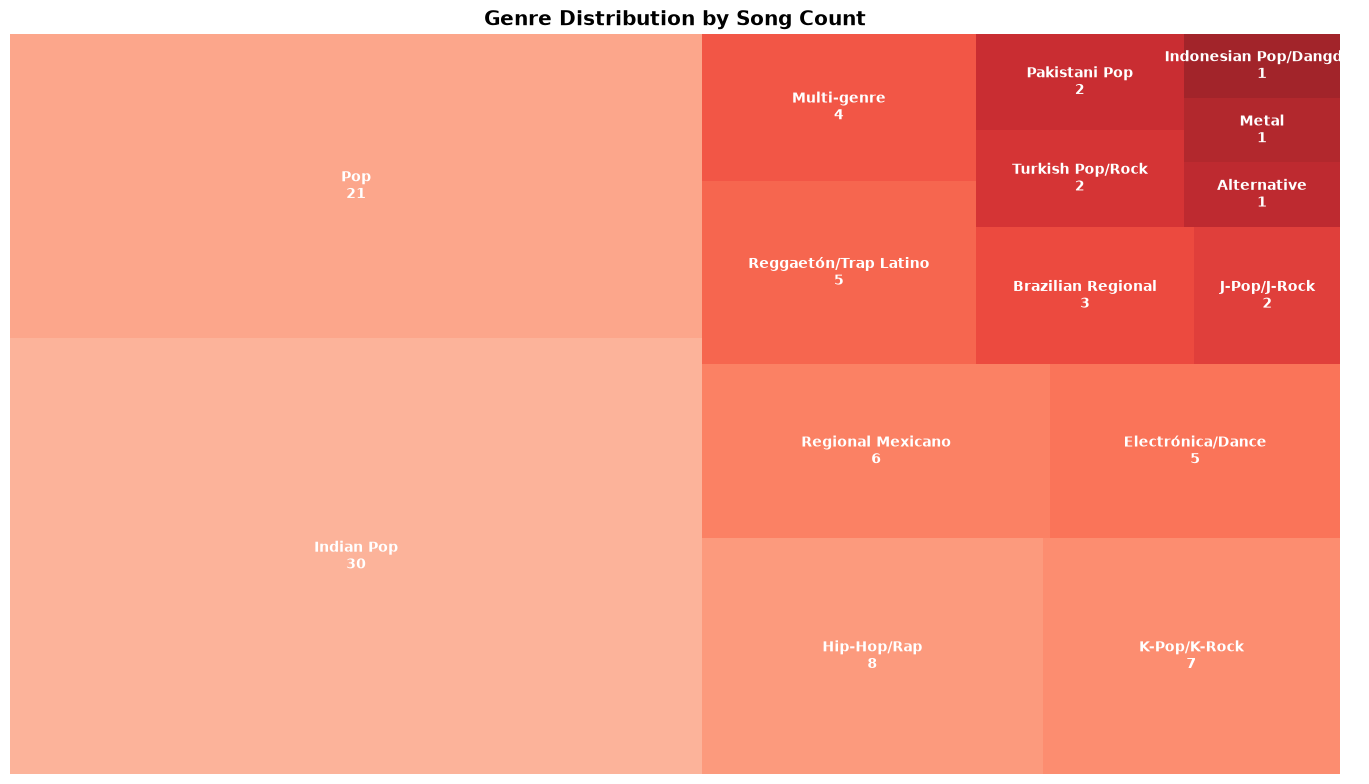

In [6]:
# Genre distribution treemap (top 15 genres)
gs = genre_stats(df).head(15)
sizes = gs['total_songs'].values
labels = [
    f"{g}\n{format_number(s)}"
    for g, s in zip(gs['macro_genre'], gs['total_songs'])
]
colors = plt.cm.Reds(np.linspace(0.3, 0.9, len(sizes)))
fig, ax = plt.subplots(figsize=(14, 8))
squarify.plot(
    sizes=sizes, label=labels, alpha=0.9, color=colors,
    text_kwargs={'fontsize': 10, 'fontweight': 'bold', 'color': 'white'},
    ax=ax,
)
ax.set_title('Genre Distribution by Song Count', fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

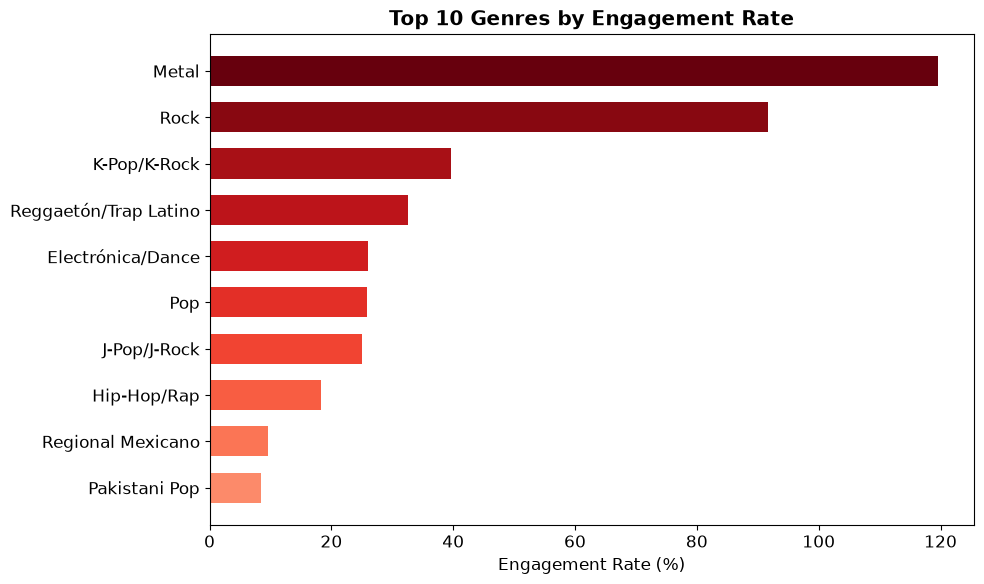

In [7]:
# Engagement rate by genre (top 10)
gs = genre_stats(df).sort_values('engagement_rate', ascending=False).head(10)
fig, ax = plt.subplots(figsize=(10, 6))
colors = plt.cm.Reds(np.linspace(0.4, 1, len(gs)))[::-1]
ax.barh(gs['macro_genre'], gs['engagement_rate'], color=colors, height=0.65)
ax.invert_yaxis()
ax.set_xlabel('Engagement Rate (%)')
ax.set_title('Top 10 Genres by Engagement Rate', fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Métricas de Video

In [8]:
vm = video_metrics(df)
display(vm)

,video_type,count,pct,avg_views,avg_engagement
0,Official,75,75.0,1.418532e+07,24.760933
1,Lyric,53,53.0,1.482320e+07,19.057736
2,Live,56,56.0,1.391142e+07,13.007500


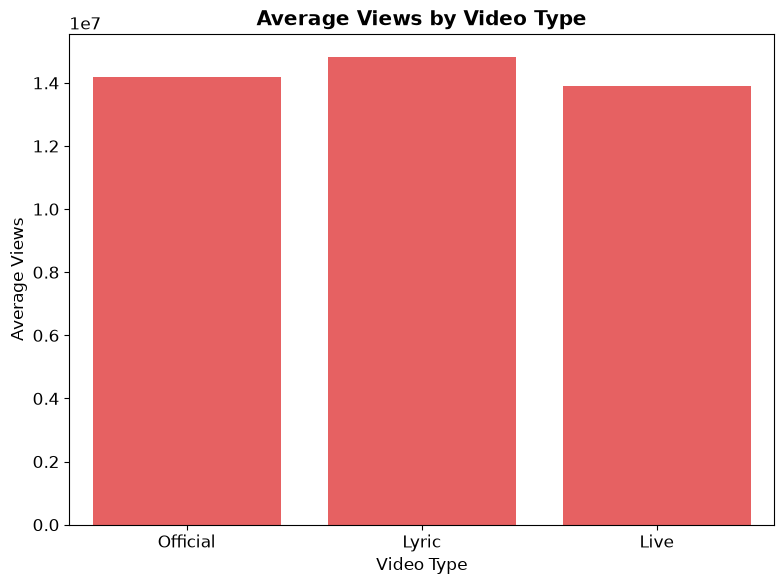

In [9]:
# Average views by video type
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=vm, x='video_type', y='avg_views', ax=ax, color='#FC4B4C')
ax.set_title('Average Views by Video Type', fontweight='bold')
ax.set_ylabel('Average Views')
ax.set_xlabel('Video Type')
plt.tight_layout()
plt.show()

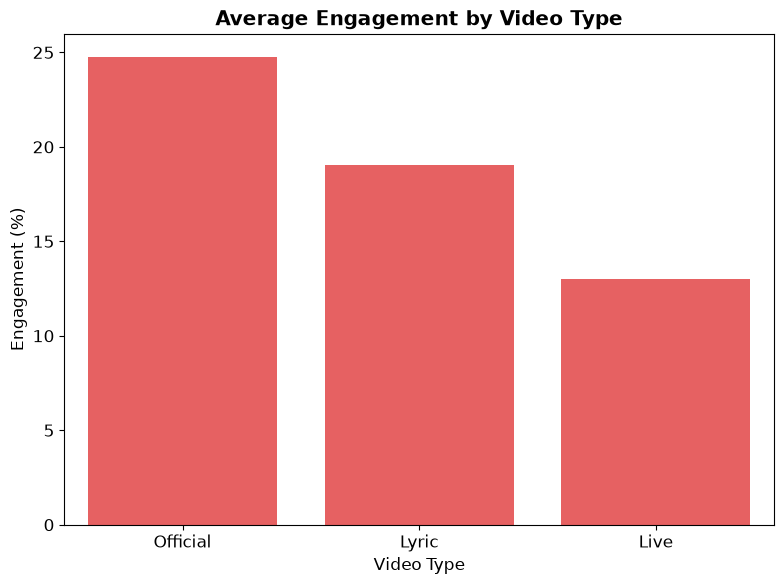

In [10]:
# Average engagement by video type
fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(data=vm, x='video_type', y='avg_engagement', ax=ax, color='#FC4B4C')
ax.set_title('Average Engagement by Video Type', fontweight='bold')
ax.set_ylabel('Engagement (%)')
ax.set_xlabel('Video Type')
plt.tight_layout()
plt.show()

## 6. Métricas de Canciones

In [11]:
# Top 10 songs by views
display(top_songs(df, metric='views', n=10))

,rank,track_name,artist_names,views,artist_country
0,1,Dai Dai,Shakira & Burna Boy,40661971,Colombia
1,2,Tu Mil Jaaye,Sachin-Jigar & Arijit Singh & Ed Sheeran & Mad...,37827726,India
2,3,POKITO,Daddy Yankee & Diljit Dosanjh,36123561,Puerto Rico
3,4,KALYANI (Remix),ARJN & KDS & FIFTY4 & Shreya Ghoshal,35997065,India
4,5,BbY WOW,KAROL G & Judeline & rusowsky,30531284,Spain
5,6,Alfaaz,Hamza Malik & Zain Zohaib,29896719,Pakistan
6,7,गुज़ारिश,Satinder Sartaaj,28263770,India
7,8,Пешта,Xamdam Sobirov,24191686,Uzbekistan
8,9,체포하겠어,ILLIT,23694267,South Korea
9,10,Casa Tupka Anthemo (feat. Priyanshi Srivastava),Yo Yo Honey Singh,23528049,India


In [12]:
# Top 10 songs by likes
display(top_songs(df, metric='likes', n=10))

,rank,track_name,artist_names,likes,artist_country
0,51,Gangnam Style (강남스타일),Psy,32383013,South Korea
1,31,Dame Tu Cosita (feat. Cutty Ranks),El Chombo,20970220,Panama
2,95,Love The Way You Lie (feat. Rihanna),Eminem,15369558,United States
3,87,Runaway,AURORA,13460586,Norway
4,40,Let Me Love You (feat. Justin Bieber),DJ Snake,12199796,France
5,61,Bring Me To Life,Evanescence,12072437,United States
6,23,Save Your Tears,The Weeknd,11135845,Canada
7,85,Poker Face,Lady Gaga,9040147,United States
8,1,Dai Dai,Shakira & Burna Boy,8878463,Colombia
9,67,November Rain,Guns N' Roses,8803207,United States


In [13]:
# Top 10 songs by engagement
display(top_songs(df, metric='engagement', n=10))

,rank,track_name,artist_names,engagement,artist_country
0,51,Gangnam Style (강남스타일),Psy,287.59,South Korea
1,95,Love The Way You Lie (feat. Rihanna),Eminem,191.14,United States
2,87,Runaway,AURORA,160.18,Norway
3,31,Dame Tu Cosita (feat. Cutty Ranks),El Chombo,149.52,Panama
4,61,Bring Me To Life,Evanescence,119.52,United States
5,85,Poker Face,Lady Gaga,107.10,United States
6,40,Let Me Love You (feat. Justin Bieber),DJ Snake,96.58,France
7,67,November Rain,Guns N' Roses,91.66,United States
8,59,All I Want for Christmas Is You,Mariah Carey,72.35,United States
9,23,Save Your Tears,The Weeknd,69.71,Canada


## 7. Análisis de Colaboraciones

In [14]:
display(collaborations(df))

,is_collaboration,count,avg_views,avg_engagement
0,Solo,81,1.368414e+07,17.934321
1,Collaboration,19,1.383371e+07,40.987368


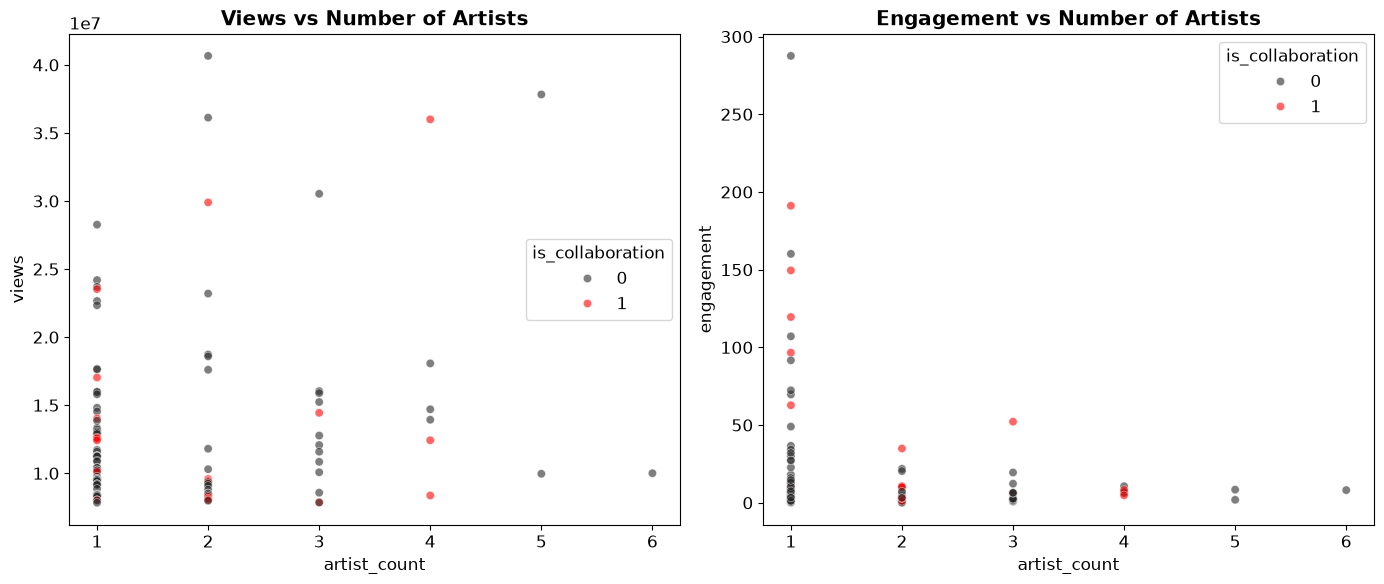

In [15]:
# Views vs number of artists
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(
    data=df, x='artist_count', y='views', hue='is_collaboration',
    palette={0: '#282828', 1: 'red'}, ax=axes[0], alpha=0.6,
)
axes[0].set_title('Views vs Number of Artists', fontweight='bold')
sns.scatterplot(
    data=df, x='artist_count', y='engagement', hue='is_collaboration',
    palette={0: '#282828', 1: 'red'}, ax=axes[1], alpha=0.6,
)
axes[1].set_title('Engagement vs Number of Artists', fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Resumen Ejecutivo

In [16]:
stats = general_stats(df)
print(f"Songs: {stats['total_songs']}")
print(f"Countries: {stats['unique_countries']}")
print(f"Genres: {stats['unique_genres']}")
print(f"Total views: {format_number(stats['total_views'])}")
print(f"Total likes: {format_number(stats['total_likes'])}")
print(f"Avg engagement: {stats['avg_engagement']:.2f}%")

Songs: 100
Countries: 26
Genres: 17
Total views: 1.4B
Total likes: 253.8M
Avg engagement: 22.31%
